# 041 — LightGBM

Preparação central original. Fit apenas no treino de cada divisão. Seleção interna/CV dentro das 8.769 linhas; validação fixa de desenvolvimento com 2.193 linhas. Sem submissão automática.

Resultado real guardado; não foi iniciado novo treino.
Kaggle: por submeter
Configuração selecionada: {'params': {'num_leaves': 31, 'learning_rate': 0.03}, 'label': "{'num_leaves': 31, 'learning_rate': 0.03}", 'iterations': 126, 'internal_macro_f1': 0.47761965520088334, 'seconds': 27.806689502000154}
CSV: {'path': 'submissions/submission_041_lightgbm.csv', 'differences': {'submission_001_regressao_logistica(1).csv': 1616, 'submission_002_regressao_logistica_regularizada.csv': 1396, 'submission_004_arvore_decisao.csv': 2037, 'submission_012_mlp_perda_ponderada.csv': 1654, 'submission_013_mlp_arquitetura.csv': 1654, 'submission_014_xgboost_mlp.csv': 888, 'submission_015_mlp_learning_rate.csv': 1539, 'submission_028_ensemble_features_dominio.csv': 902, 'submission_029_catboost.csv': 1288, 'submission_031_catboost_ponderacao_suave.csv': 1309, 'submission_034_ensemble_catboost_ponderado.csv': 933, 'submission_037_novo_modelo.csv': 1467, 'submission_038_novo_modelo.csv': 1285, 'submission_03

,parcela,Macro F1,accuracy
0,train,0.988172,0.984719
1,validation,0.458744,0.461924


,classe,escalão,F1,recall,support
0,0,15–17 anos,0.823529,0.853659,41
1,1,18–19 anos,0.408163,0.294118,34
2,2,20–24 anos,0.632184,0.687500,80
3,3,25–29 anos,0.351145,0.306667,75
4,4,30–34 anos,0.270270,0.222222,90
5,5,35–39 anos,0.322097,0.333333,129
6,6,40–44 anos,0.363144,0.389535,172
7,7,45–49 anos,0.372493,0.375723,173
8,8,50–54 anos,0.619048,0.646409,181
9,9,55–59 anos,0.616137,0.620690,203


,params,label,iterations,internal_macro_f1,seconds
0,"{'num_leaves': 15, 'learning_rate': 0.03}","{'num_leaves': 15, 'learning_rate': 0.03}",169,0.477457,25.396576
1,"{'num_leaves': 15, 'learning_rate': 0.1}","{'num_leaves': 15, 'learning_rate': 0.1}",40,0.471293,9.180564
2,"{'num_leaves': 31, 'learning_rate': 0.03}","{'num_leaves': 31, 'learning_rate': 0.03}",126,0.477620,27.806690
3,"{'num_leaves': 31, 'learning_rate': 0.1}","{'num_leaves': 31, 'learning_rate': 0.1}",84,0.474099,21.190011


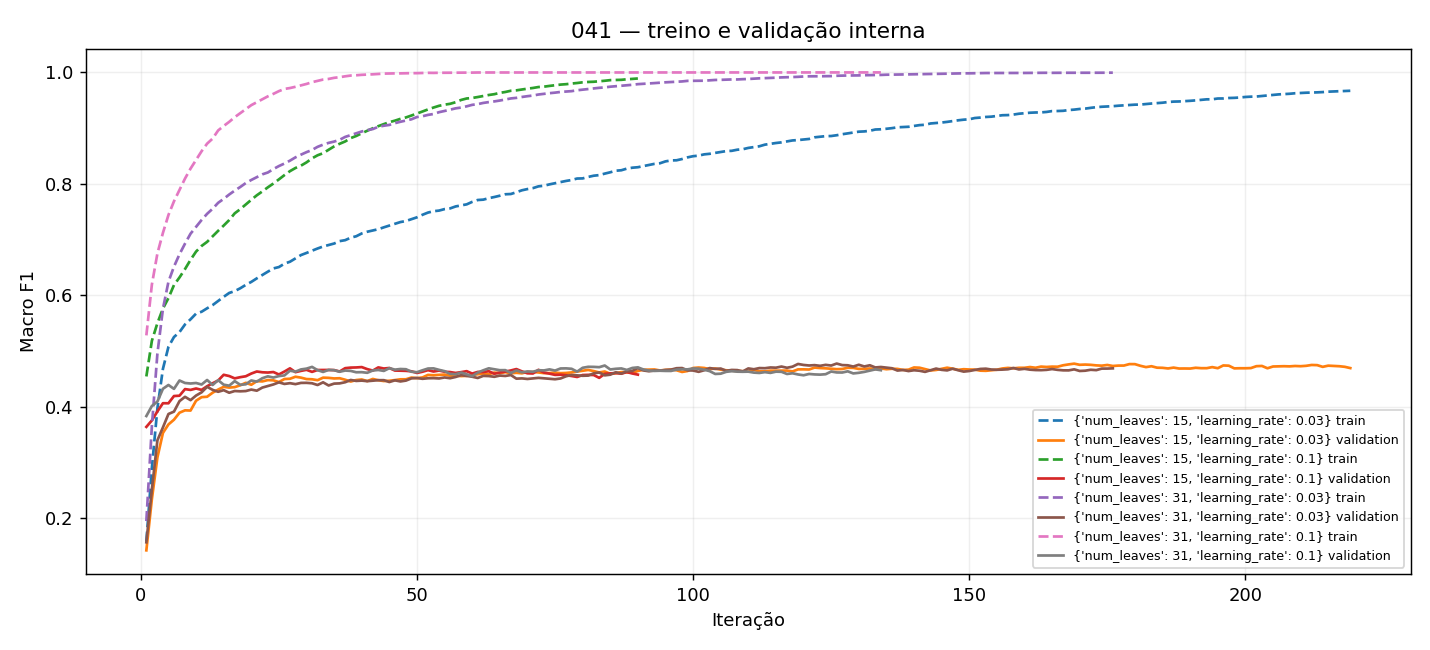

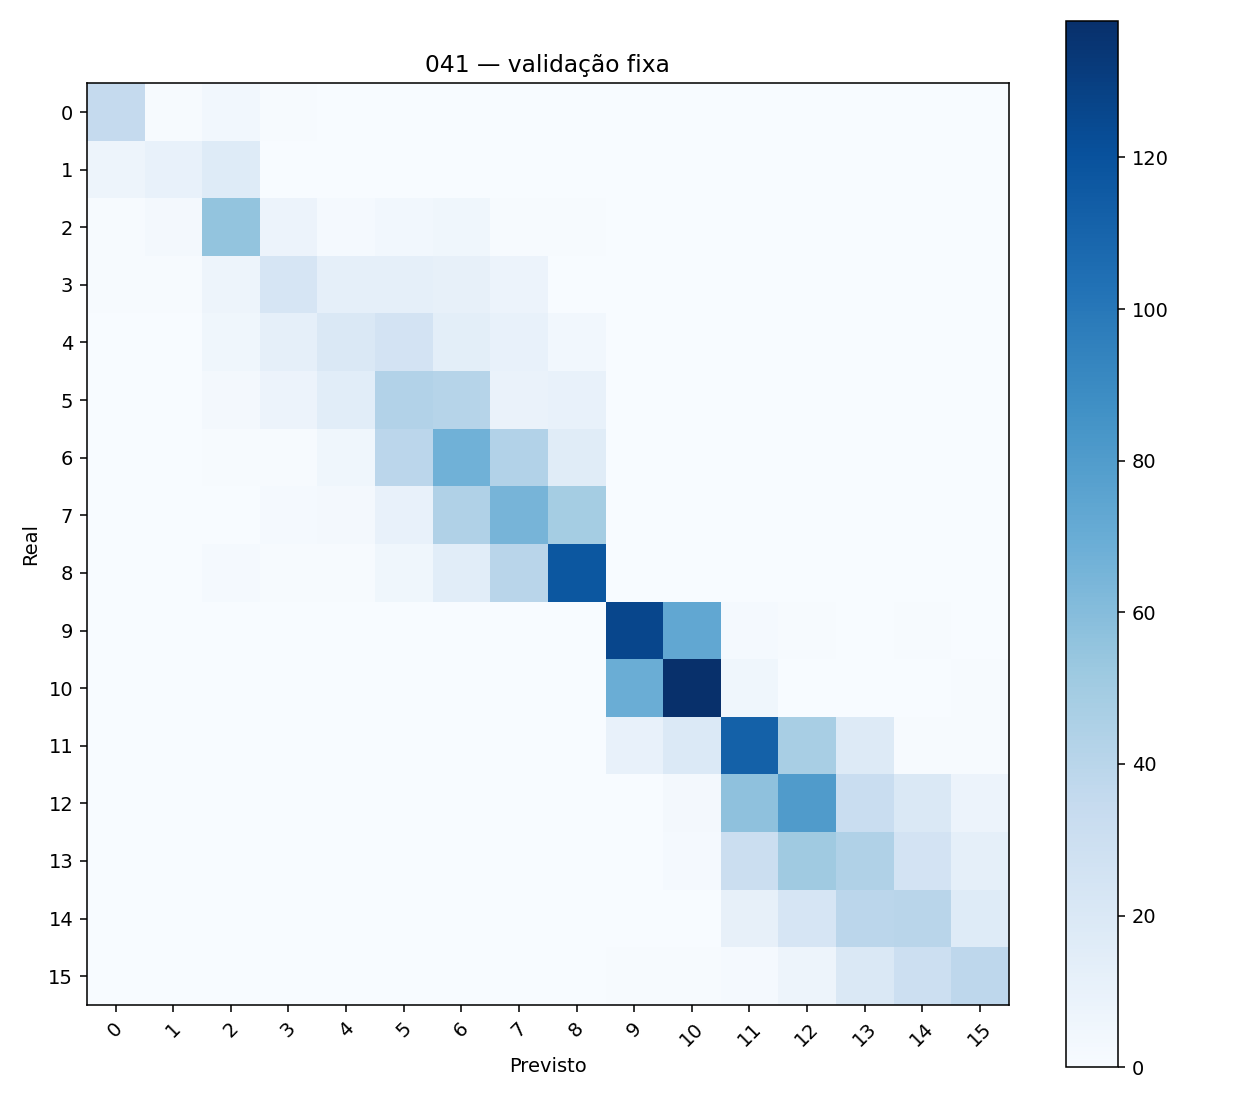

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'src/ver_resultados.py').is_file())
sys.path.insert(0, str(root))
from src.ver_resultados import carregar_resultado
result = carregar_resultado('041')
print('Resultado real guardado; não foi iniciado novo treino.')
print('Kaggle: por submeter')
selected = result.get('selected_internally', result.get('selected'))
if isinstance(selected, dict): selected = {k:v for k,v in selected.items() if k not in ['history', 'ae', 'folds']}
print('Configuração selecionada:', selected)
metrics = result.get('fixed_metrics', result.get('metrics', {}))
if metrics:
    display(pd.DataFrame([{'parcela':k, 'Macro F1':m['macro_f1'], 'accuracy':m['accuracy']} for k,m in metrics.items() if isinstance(m,dict) and 'macro_f1' in m]))
    if 'validation' in metrics:
        detail = metrics['validation'].get('per_class', metrics['validation'].get('classification_report', {}))
        if detail: display(pd.DataFrame(detail))
rows = result.get('candidates', result.get('results', []))
if rows:
    display(pd.DataFrame([{k:v for k,v in r.items() if k not in ['history','ae','folds','age_profile_posthoc','sizes']} for r in rows]))
images = list((root/'reports').glob('experiencia_041_*.png')) + list((root/'reports').glob('041*.png'))
for p in sorted(set(images)): display(Image(filename=str(p)))
print('CSV:', result.get('submission'))
print('Notas:', result.get('note', ''))


## Conclusão e Decisão
- Data: 17/11
- Resultado local próximo do ensemble 025, mas inferior no Kaggle (0,44). A proximidade local não se traduziu numa melhoria pública.
- Pontuação Kaggle: 0.44
- Melhorias: Testar min_child_samples, L1/L2 e ponderação das classes. Só depois avaliar uma mistura com MLP, selecionada internamente.